# 3. Distribution analysis

Explore variable shape and concentration, identify potential outliers, and compare distributions across meaningful groups.

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/final_destination.csv")


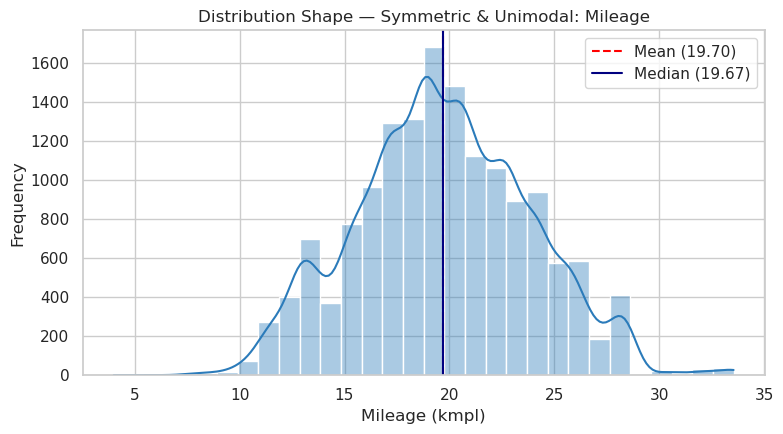

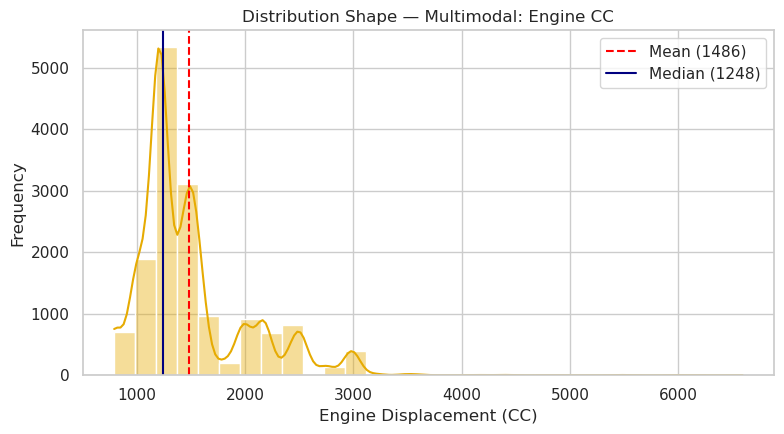

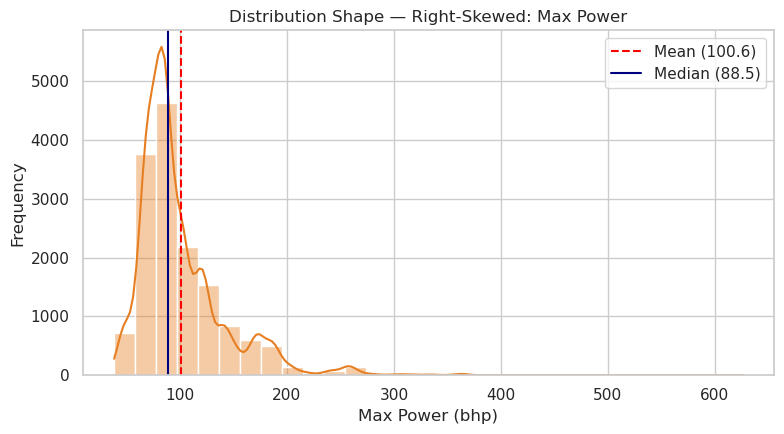

In [42]:
### 1. Distribution Shape (Histograms + KDE — Separate Plots)
  #### Plot 1A: Symmetric & Unimodal (mileage)
plt.figure(figsize=(8, 4.5))
sns.histplot(df["mileage"], kde=True, bins=30, color="#2b7bba", alpha=0.4)
plt.axvline(df["mileage"].mean(), color="red", linestyle="--", label=f"Mean ({df['mileage'].mean():.2f})")
plt.axvline(df["mileage"].median(), color="navy", linestyle="-", label=f"Median ({df['mileage'].median():.2f})")
plt.title("Distribution Shape — Symmetric & Unimodal: Mileage")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()
  #### Plot 1B: Multimodal (engine)
plt.figure(figsize=(8, 4.5))
sns.histplot(df["engine"], kde=True, bins=30, color="#e6ab02", alpha=0.4)
plt.axvline(df["engine"].mean(), color="red", linestyle="--", label=f"Mean ({df['engine'].mean():.0f})")
plt.axvline(df["engine"].median(), color="navy", linestyle="-", label=f"Median ({df['engine'].median():.0f})")
plt.title("Distribution Shape — Multimodal: Engine CC")
plt.xlabel("Engine Displacement (CC)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()
  #### Plot 1C: Right-Skewed (max_power)

plt.figure(figsize=(8, 4.5))
sns.histplot(df["max_power"], kde=True, bins=30, color="#e67e22", alpha=0.4)
plt.axvline(df["max_power"].mean(), color="red", linestyle="--", label=f"Mean ({df['max_power'].mean():.1f})")
plt.axvline(df["max_power"].median(), color="navy", linestyle="-", label=f"Median ({df['max_power'].median():.1f})")
plt.title("Distribution Shape — Right-Skewed: Max Power")
plt.xlabel("Max Power (bhp)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


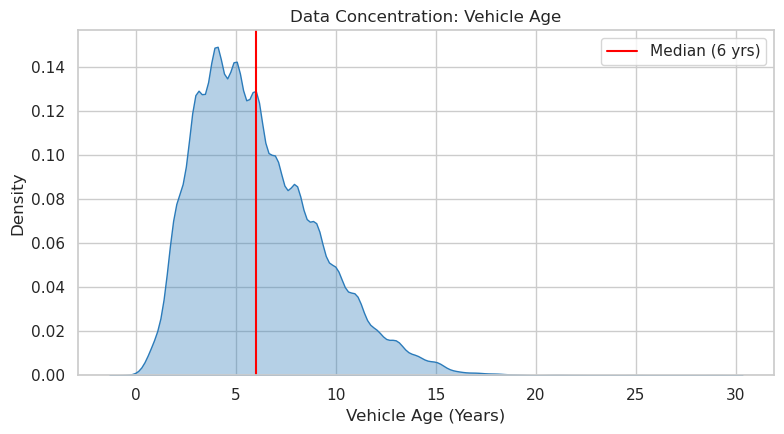

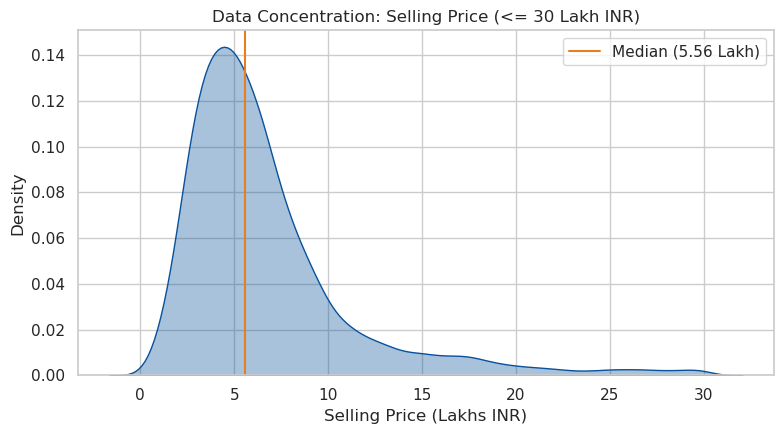

In [43]:
 ### 2. Data Concentration (KDE Plots — Separate Plots)

#### Plot 2A: Concentration of vehicle_age

plt.figure(figsize=(8, 4.5))
sns.kdeplot(df["vehicle_age"], fill=True, color="#2b7bba", alpha=0.35)
plt.axvline(df["vehicle_age"].median(), color="red", linestyle="-", label="Median (6 yrs)")
plt.title("Data Concentration: Vehicle Age")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
#### Plot 2B: Concentration of selling_price
plt.figure(figsize=(8, 4.5))
sns.kdeplot(df[df["selling_price"] <= 3000000]["selling_price"] / 1e5, fill=True, color="#08519c", alpha=0.35)
plt.axvline(df["selling_price"].median() / 1e5, color="#e67e22", linestyle="-", label="Median (5.56 Lakh)")
plt.title("Data Concentration: Selling Price (<= 30 Lakh INR)")
plt.xlabel("Selling Price (Lakhs INR)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


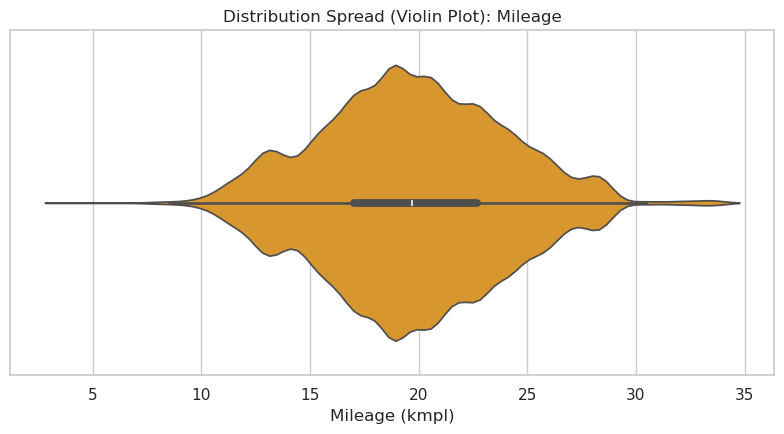

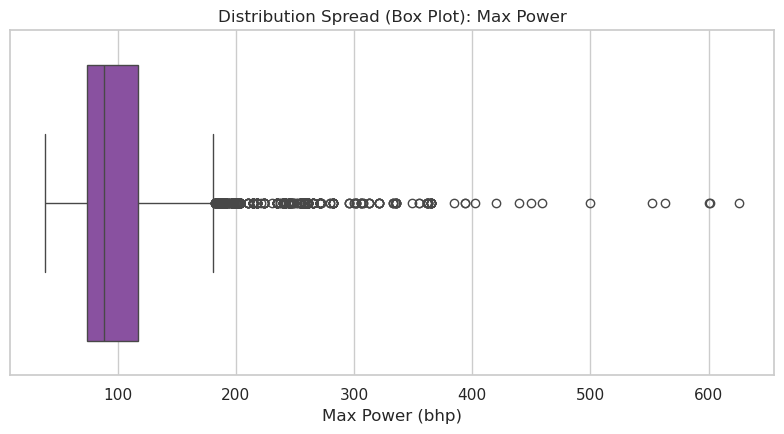

In [44]:
  ### 3. Distribution Spread (Violin Plot & Box Plot — Separate Plots)
#### Plot 3A: Violin Plot (mileage)
plt.figure(figsize=(8, 4.5))
sns.violinplot(x=df["mileage"], color="#f39c12", inner="box")
plt.title("Distribution Spread (Violin Plot): Mileage")
plt.xlabel("Mileage (kmpl)")
plt.tight_layout()
plt.show()
#### Plot 3B: Box Plot (max_power)
plt.figure(figsize=(8, 4.5))
sns.boxplot(x=df["max_power"], color="#8e44ad")
plt.title("Distribution Spread (Box Plot): Max Power")
plt.xlabel("Max Power (bhp)")
plt.tight_layout()
plt.show()


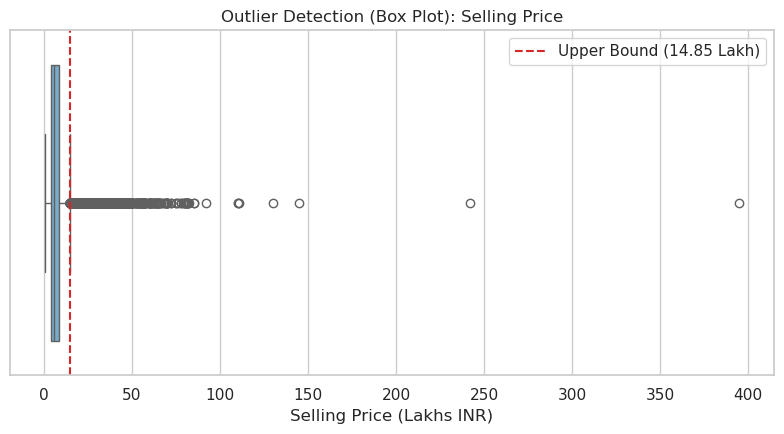

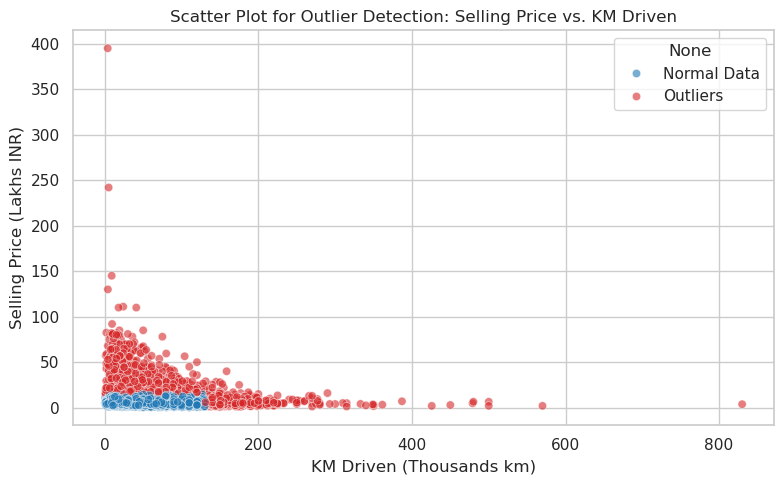

In [45]:
 ### 4. Outlier Detection (IQR Rule: Box Plot & Scatter Plot — Separate Plots)
  #### Plot 4A: Box Plot (selling_price Outliers)
q1_p, q3_p = df["selling_price"].quantile([0.25, 0.75])
upper_p = q3_p + 1.5 * (q3_p - q1_p)

plt.figure(figsize=(8, 4.5))
sns.boxplot(x=df["selling_price"] / 1e5, color="#6baed6")
plt.axvline(upper_p / 1e5, color="#d62728", linestyle="--", label=f"Upper Bound ({upper_p/1e5:.2f} Lakh)")
plt.title("Outlier Detection (Box Plot): Selling Price")
plt.xlabel("Selling Price (Lakhs INR)")
plt.legend()
plt.tight_layout()
plt.show()

  #### Plot 4B: Scatter Plot (selling_price vs. km_driven Outliers)
q1_p, q3_p = df["selling_price"].quantile([0.25, 0.75])
upper_p = q3_p + 1.5 * (q3_p - q1_p)

q1_k, q3_k = df["km_driven"].quantile([0.25, 0.75])
upper_k = q3_k + 1.5 * (q3_k - q1_k)

outliers = ((df["selling_price"] > upper_p) | (df["km_driven"] > upper_k)).map(
    {False: "Normal Data", True: "Outliers"}
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
        x=df["km_driven"] / 1e3,
        y=df["selling_price"] / 1e5,
        hue=outliers,
        palette={"Normal Data": "#1f77b4", "Outliers": "#d62728"},
        alpha=0.6
    )
plt.title("Scatter Plot for Outlier Detection: Selling Price vs. KM Driven")
plt.xlabel("KM Driven (Thousands km)")
plt.ylabel("Selling Price (Lakhs INR)")
plt.tight_layout()
plt.show()


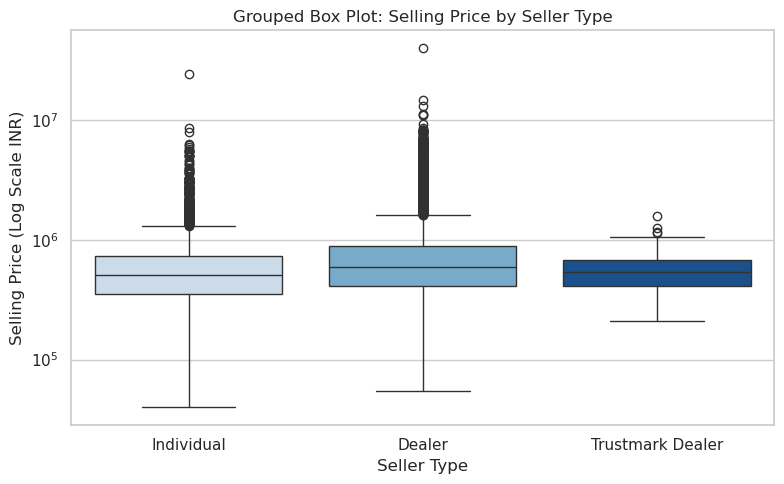

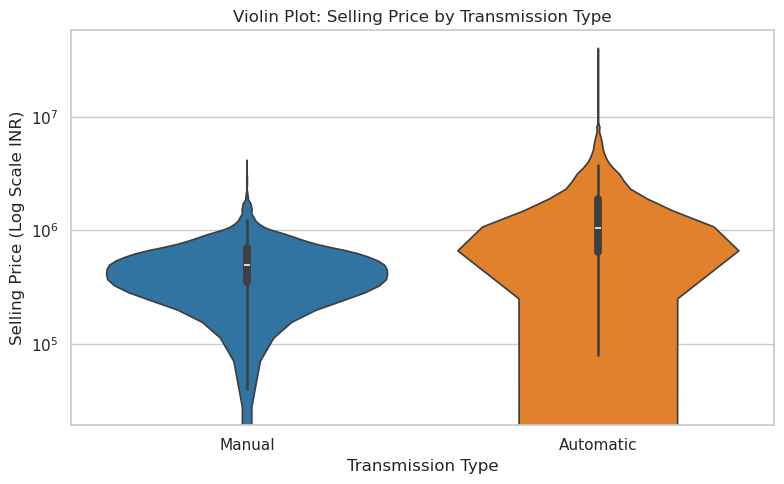

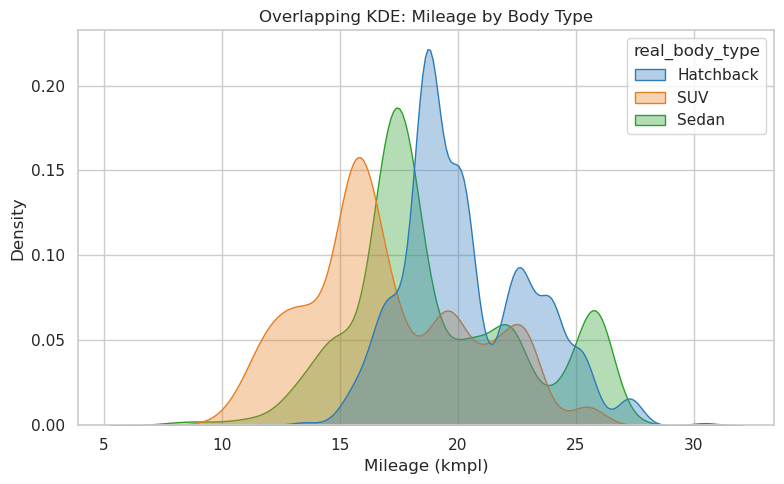

In [46]:
  ### 5. Distribution Comparison Across Categories (Separate Plots)
  #### Plot 5A: Grouped Box Plot (selling_price by seller_type — Monochromatic Blue)
plt.figure(figsize=(8, 5))
sns.boxplot(
        data=df,
        x="seller_type",
        y="selling_price",
        order=["Individual", "Dealer", "Trustmark Dealer"],
        hue="seller_type",
        palette=["#c6dbef", "#6baed6", "#08519c"],
        legend=False
    )
plt.yscale("log")
plt.title("Grouped Box Plot: Selling Price by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price (Log Scale INR)")
plt.tight_layout()
plt.show()

  #### Plot 5B: Grouped Violin Plot (selling_price by transmission_type — Complementary Blue & Orange)

plt.figure(figsize=(8, 5))
sns.violinplot(
        data=df,
        x="transmission_type",
        y="selling_price",
        hue="transmission_type",
        palette=["#1f77b4", "#ff7f0e"],
        inner="box",
        legend=False
    )
plt.yscale("log")
plt.title("Violin Plot: Selling Price by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (Log Scale INR)")
plt.tight_layout()
plt.show()

  #### Plot 5C: Overlapping Density Plot (mileage by real_body_type — Triadic Colors)

body_df = df[df["real_body_type"].isin(["Hatchback", "Sedan", "SUV"])]

plt.figure(figsize=(8, 5))
sns.kdeplot(
        data=body_df,
        x="mileage",
        hue="real_body_type",
        palette=["#2b7bba", "#e67e22", "#2ca02c"],
        fill=True,
        common_norm=False,
        alpha=0.35
    )
plt.title("Overlapping KDE: Mileage by Body Type")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()
